<a href="https://colab.research.google.com/github/mdnazishpatel/Machine_learning/blob/main/PyTorch_workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###PyTorch Workflow

In [210]:
### PyTorch Workflow
what_iam_going_todo = {
     1: "data (prepare and load)",
     2: "build model",
     3: "fitting the model to data (training)",
     4: "making predictions and evaluating a model (inference)",
     5: "putting it all together"
 }
what_iam_going_todo

{1: 'data (prepare and load)',
 2: 'build model',
 3: 'fitting the model to data (training)',
 4: 'making predictions and evaluating a model (inference)',
 5: 'putting it all together'}

In [211]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.__version__

'2.14.1+cpu'

## Data preparing -  `(data can be anything and converting any data into numerical type)`

In [212]:
## Lenear Regression formula

weight = 0.7
bias = 0.3
start = 0
end = 1
step = 0.02

X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias

X[:10], y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [213]:
len(X), len(y)

(50, 50)

In [214]:
## Creating a train/test split
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

Visulaizing our data through matplotlib

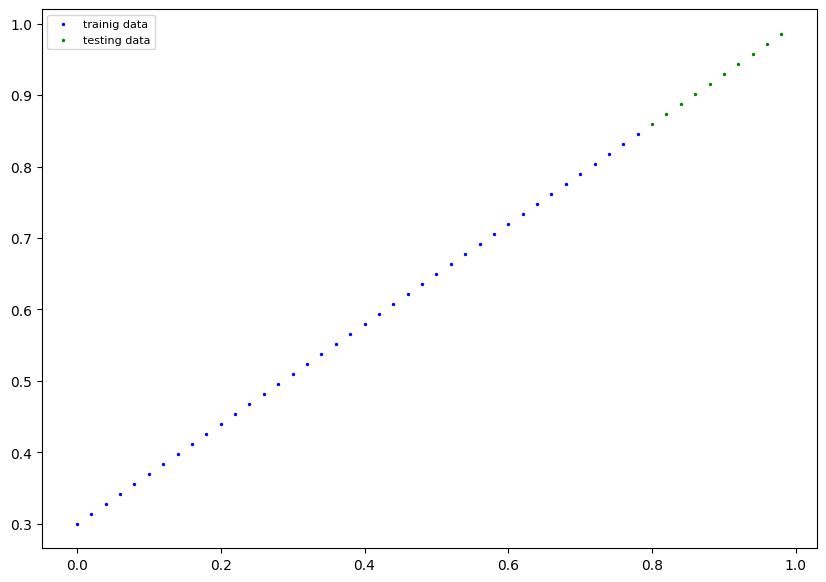

In [215]:
from prompt_toolkit.shortcuts.progress_bar import Label
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):
  """
  plots training data,test data and compares predictions
  """
  plt.figure(figsize=(10,7))
  #plot tarining data in blue
  plt.scatter(train_data, train_labels, c="b", s=2, label="trainig data")

  #plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=2, label="testing data")

  # predicitons
  if predictions is not None:
   plt.scatter(test_data, predictions, c="r", s=2, label="predictions")

  plt.legend(prop={"size": 8})
plot_predictions()

## BUILDIND MODEL - Lenear regression

In [216]:
class LinearRegressionModel(nn.Module): #-> alomst everything in pytorch is inherited by nn.modeule
  def __init__(self):
    super().__init__()
    #Initilize model parameter
    self.weights = nn.Parameter(torch.randn(1,
                                            requires_grad=True,
                                            dtype=torch.float))
    self.bias = nn.Parameter(torch.randn(1,
                                         requires_grad=True,
                                         dtype=torch.float))
    #forward() defines the computation in the model
  def forward(self, X:torch.Tensor) -> torch.Tensor:
      return self.weights * X + self.bias ##Linear regression formula



In [217]:
torch.manual_seed(42)
model_0 = LinearRegressionModel()
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [218]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [219]:
weight , bias

(0.7, 0.3)

In [220]:
## Making predictions using toch.inference_module()
## inference mode does not track gradient that's why we use it
with torch.inference_mode():
  y_preds = model_0(X_test)

y_preds


tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

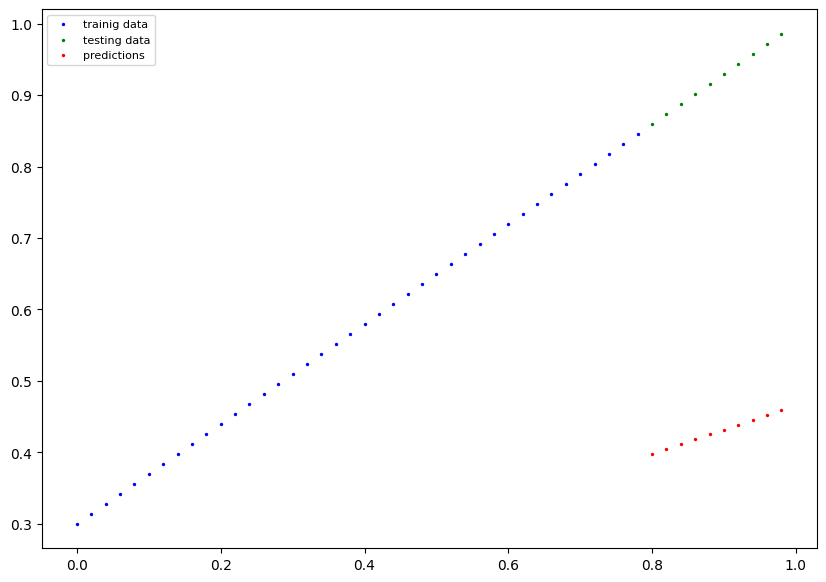

In [221]:
plot_predictions(predictions=y_preds)

 ### Training a model.
  so the whole idea of training a model is move unkown parameters to known parameters basically better representation of data
  So we use loss function for it

  **Loss function** : a function that measures how wrong the predictions is to the ideal output
  
  **Optimizer** : Takes account the loss of a model ad adjust the parameters (weights, bias)

In [222]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params=model_0.parameters(),
                            lr=0.01)

In [227]:

epoches = 50  # one loop through data
for epoch in range(epoches):
  # setting the model into training mode
  model_0.train()
  # Forawrdpass()
  y_preds = model_0(X_train)
  # Calculate loss
  loss = loss_fn(y_preds, y_train)
  print(f"loss = {loss}")
  # Optimizer zero grad
  optimizer.zero_grad()
  # perform backpropagatation on the loss
  loss.backward()
  # perform gardient descent
  optimizer.step()
  model_0.eval()
  print(model_0.state_dict())

loss = 0.04167863354086876
OrderedDict({'weights': tensor([0.4938]), 'bias': tensor([0.3843])})
loss = 0.04132963344454765
OrderedDict({'weights': tensor([0.4956]), 'bias': tensor([0.3838])})
loss = 0.04098063334822655
OrderedDict({'weights': tensor([0.4974]), 'bias': tensor([0.3833])})
loss = 0.04063162952661514
OrderedDict({'weights': tensor([0.4992]), 'bias': tensor([0.3828])})
loss = 0.040282636880874634
OrderedDict({'weights': tensor([0.5010]), 'bias': tensor([0.3823])})
loss = 0.039933640509843826
OrderedDict({'weights': tensor([0.5028]), 'bias': tensor([0.3818])})
loss = 0.03958464413881302
OrderedDict({'weights': tensor([0.5046]), 'bias': tensor([0.3813])})
loss = 0.03923564404249191
OrderedDict({'weights': tensor([0.5064]), 'bias': tensor([0.3808])})
loss = 0.03888664394617081
OrderedDict({'weights': tensor([0.5082]), 'bias': tensor([0.3803])})
loss = 0.0385376438498497
OrderedDict({'weights': tensor([0.5100]), 'bias': tensor([0.3798])})
loss = 0.03818932920694351
OrderedDict(

In [228]:
with torch.inference_mode():
  y_preds_new = model_0(X_test)

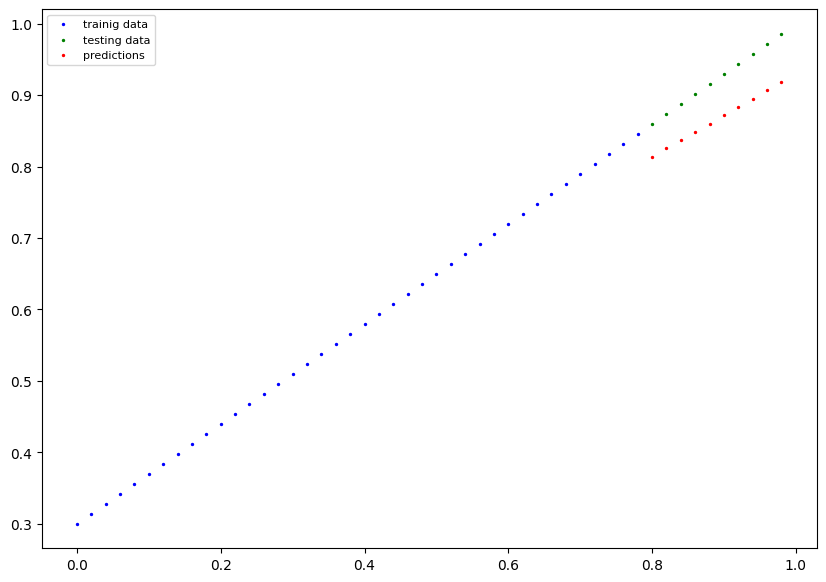

In [229]:
plot_predictions(predictions=y_preds_new)

In [226]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.4920])), ('bias', tensor([0.3848]))])